# 01 · Data Loading and Sampling

**Use Case 3: Research Paper Analysis and Recommendation System**

The full arXiv metadata snapshot is ~5.6 GB with ~3.2M records (one JSON object per line), which is too large to load into memory. This notebook streams the file once and draws a reproducible, class-balanced random sample of Computer Science papers. Later notebooks read the cached sample, not the raw file.

**Sampling design**
- Keep papers whose *primary* category (first listed) is one of a fixed set of CS sub-fields. That gives clean labels for research-domain classification.
- Use reservoir sampling per category, so every category gets the same number of papers and each paper in it has an equal chance of being picked.
- Fix the random seed so results can be reproduced.

In [3]:
import gzip
import json
import os
import random
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

## Configuration

`ARXIV_PATH` defaults to the raw snapshot kept outside the submission folder. Set the `ARXIV_PATH` environment variable to override it. The raw file is **not** part of the submission zip, but the small cached sample in `codes/data/` can be.

In [4]:
ARXIV_PATH = Path(os.environ.get("ARXIV_PATH", "../../dataset/arxiv-metadata-oai-snapshot.json"))
SAMPLE_PATH = Path("data/arxiv_cs_sample.jsonl.gz")

TARGET_CATEGORIES = ["cs.CL", "cs.CV", "cs.LG", "cs.AI", "cs.IR", "cs.CR"]
PER_CATEGORY = 2000
SEED = 42

FIELDS = ["id", "title", "abstract", "authors", "authors_parsed", "categories",
          "doi", "journal-ref", "update_date", "versions"]

## Stream and sample

A cheap substring check skips most non-CS lines before `json.loads`, so one pass over the file takes a few minutes. If the cached sample already exists, it is loaded instead.

In [5]:
def reservoir_sample(path, categories, k, seed):
    """Return up to k random records per primary category in a single pass."""
    rng = random.Random(seed)
    targets = set(categories)
    reservoirs = defaultdict(list)
    seen = defaultdict(int)
    with open(path, encoding="utf-8") as f:
        for line in f:
            if '"categories":"cs.' not in line:
                continue
            rec = json.loads(line)
            primary = rec["categories"].split()[0]
            if primary not in targets:
                continue
            seen[primary] += 1
            row = {key: rec.get(key) for key in FIELDS}
            bucket = reservoirs[primary]
            if len(bucket) < k:
                bucket.append(row)
            else:
                j = rng.randrange(seen[primary])
                if j < k:
                    bucket[j] = row
    return [r for c in categories for r in reservoirs[c]], dict(seen)


if SAMPLE_PATH.exists():
    with gzip.open(SAMPLE_PATH, "rt", encoding="utf-8") as f:
        records = [json.loads(line) for line in f]
    print(f"Loaded {len(records):,} cached records from {SAMPLE_PATH}")
else:
    records, population = reservoir_sample(ARXIV_PATH, TARGET_CATEGORIES, PER_CATEGORY, SEED)
    SAMPLE_PATH.parent.mkdir(parents=True, exist_ok=True)
    with gzip.open(SAMPLE_PATH, "wt", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")
    print("Papers per primary category in the full snapshot:", population)
    print(f"Sampled {len(records):,} records -> {SAMPLE_PATH}")

Loaded 12,000 cached records from data/arxiv_cs_sample.jsonl.gz


## Build the DataFrame

Light cleaning only: collapse the hard line-wraps in titles and abstracts, derive the primary category (classification label) and the first-submission year, and turn `authors_parsed` into readable names. Heavier preprocessing (tokenisation, lemmatisation, stop-words) belongs in the next notebook.

In [6]:
def clean_ws(text):
    return re.sub(r"\s+", " ", text or "").strip()


df = pd.DataFrame(records)
df["title"] = df["title"].map(clean_ws)
df["abstract"] = df["abstract"].map(clean_ws)
df["primary_category"] = df["categories"].str.split().str[0]
df["all_categories"] = df["categories"].str.split()
df["year"] = pd.to_datetime(df["versions"].map(lambda v: v[0]["created"]),
                            format="%a, %d %b %Y %H:%M:%S %Z").dt.year
df["author_list"] = df["authors_parsed"].map(
    lambda names: [" ".join(p for p in (n[1], n[0]) if p) for n in names])
df["n_authors"] = df["author_list"].str.len()
df["abstract_words"] = df["abstract"].str.split().str.len()

df = df.drop(columns=["versions", "authors_parsed"]).drop_duplicates("id").reset_index(drop=True)
df.head(10)

,id,title,abstract,authors,categories,doi,journal-ref,update_date,primary_category,all_categories,year,author_list,n_authors,abstract_words
0,2404.00934,ChatGLM-RLHF: Practices of Aligning Large Lang...,ChatGLM is a free-to-use AI service powered by...,"Zhenyu Hou, Yilin Niu, Zhengxiao Du, Xiaohan Z...",cs.CL,NaN,NaN,2024-04-04,cs.CL,[cs.CL],2024,"[Zhenyu Hou, Yilin Niu, Zhengxiao Du, Xiaohan ...",11,162
1,2410.18225,Generalizations across filler-gap dependencies...,Humans develop their grammars by making struct...,"Katherine Howitt, Sathvik Nair, Allison Dods a...",cs.CL,NaN,NaN,2024-10-25,cs.CL,[cs.CL],2024,"[Katherine Howitt, Sathvik Nair, Allison Dods,...",4,95
2,2304.01712,Rumour Detection and Analysis on Twitter,In recent years people have become increasingl...,Yaohou Fan,cs.CL cs.AI,NaN,NaN,2023-04-05,cs.CL,"[cs.CL, cs.AI]",2023,[Yaohou Fan],1,171
3,2509.24120,EduVidQA: Generating and Evaluating Long-form ...,As digital platforms redefine educational para...,"Sourjyadip Ray, Shubham Sharma, Somak Aditya, ...",cs.CL,NaN,NaN,2025-09-30,cs.CL,[cs.CL],2025,"[Sourjyadip Ray, Shubham Sharma, Somak Aditya,...",4,178
4,1706.03747,Acoustic data-driven lexicon learning based on...,Speech recognition systems for irregularly-spe...,"Xiaohui Zhang, Vimal Manohar, Daniel Povey, Sa...",cs.CL,NaN,NaN,2017-06-13,cs.CL,[cs.CL],2017,"[Xiaohui Zhang, Vimal Manohar, Daniel Povey, S...",4,148
5,1805.04793,Coarse-to-Fine Decoding for Neural Semantic Pa...,Semantic parsing aims at mapping natural langu...,"Li Dong, Mirella Lapata",cs.CL,NaN,NaN,2018-05-15,cs.CL,[cs.CL],2018,"[Li Dong, Mirella Lapata]",2,102
6,2506.20923,KaLM-Embedding-V2: Superior Training Technique...,Recent advancements in Large Language Models (...,"Xinping Zhao, Xinshuo Hu, Zifei Shan, Shouzhen...",cs.CL,NaN,NaN,2026-09-04,cs.CL,[cs.CL],2025,"[Xinping Zhao, Xinshuo Hu, Zifei Shan, Shouzhe...",17,221
7,2110.00735,Simplify Your Law: Using Information Theory to...,Textual redundancy is one of the main challeng...,"Corinna Coupette, Jyotsna Singh, Holger Spamann",cs.CL cs.CY cs.IT cs.SE math.IT,10.1109/ICDMW53433.2021.00083,NaN,2022-05-10,cs.CL,"[cs.CL, cs.CY, cs.IT, cs.SE, math.IT]",2021,"[Corinna Coupette, Jyotsna Singh, Holger Spamann]",3,110
8,2512.01191,Generalist Large Language Models Outperform Cl...,Specialized clinical AI assistants are rapidly...,"Krithik Vishwanath, Mrigayu Ghosh, Anton Alyak...",cs.CL,NaN,NaN,2025-12-02,cs.CL,[cs.CL],2025,"[Krithik Vishwanath, Mrigayu Ghosh, Anton Alya...",6,146
9,1705.01306,Amobee at SemEval-2017 Task 4: Deep Learning S...,This paper describes the Amobee sentiment anal...,"Alon Rozental, Daniel Fleischer",cs.CL stat.ML,10.18653/v1/S17-2108,NaN,2018-07-24,cs.CL,"[cs.CL, stat.ML]",2017,"[Alon Rozental, Daniel Fleischer]",2,66


## Quick look at the sample

In [7]:
print(df.shape)
print(df["primary_category"].value_counts())
df[["year", "n_authors", "abstract_words"]].describe().round(1)

(12000, 14)
primary_category
cs.CL    2000
cs.CV    2000
cs.LG    2000
cs.AI    2000
cs.IR    2000
cs.CR    2000
Name: count, dtype: int64


,year,n_authors,abstract_words
count,12000.0,12000.0,12000.0
mean,2022.3,4.6,173.7
std,3.9,3.4,48.2
min,1994.0,1.0,4.0
25%,2021.0,3.0,141.0
50%,2024.0,4.0,173.0
75%,2025.0,6.0,206.0
max,2026.0,75.0,552.0


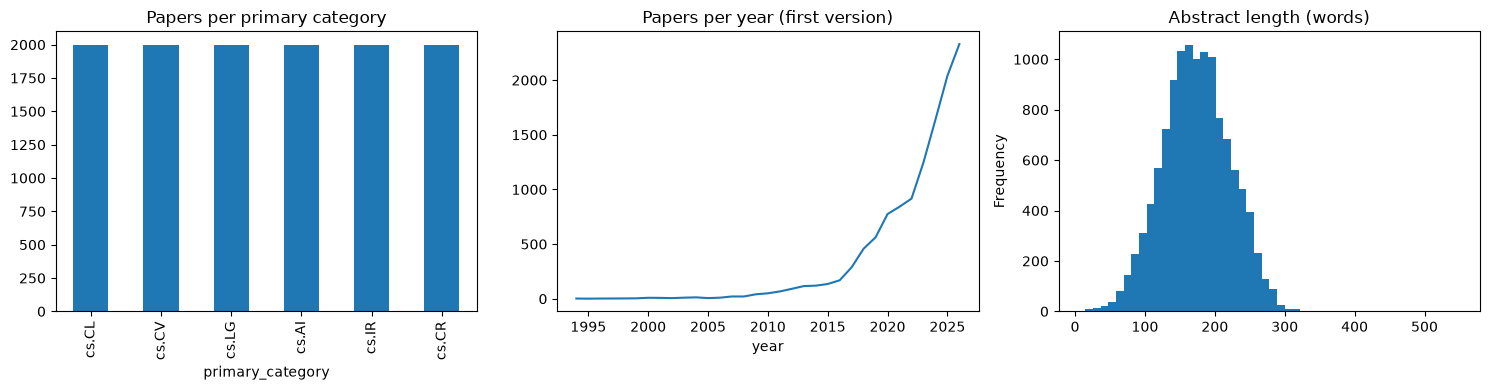

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["primary_category"].value_counts().plot.bar(ax=axes[0], title="Papers per primary category")
df["year"].value_counts().sort_index().plot(ax=axes[1], title="Papers per year (first version)")
df["abstract_words"].plot.hist(bins=50, ax=axes[2], title="Abstract length (words)")
plt.tight_layout()
plt.show()

In [9]:
# How often papers are cross-listed: useful context when interpreting classification errors
df["n_categories"] = df["all_categories"].str.len()
print("Share cross-listed in >1 category:", round((df["n_categories"] > 1).mean(), 3))
df.groupby("primary_category")["n_categories"].mean().round(2)

Share cross-listed in >1 category: 0.544


primary_category
cs.AI    1.77
cs.CL    1.78
cs.CR    1.78
cs.CV    1.59
cs.IR    1.85
cs.LG    2.19
Name: n_categories, dtype: float64

## Shared train/test split

One stratified 80/20 split, saved by paper ID, so every notebook evaluates on the same held-out papers. Load it with `utils.load_split()`.

In [10]:
from sklearn.model_selection import train_test_split

SPLIT_PATH = Path("data/split_ids.json")
train_ids, test_ids = train_test_split(df["id"], test_size=0.2, stratify=df["primary_category"],
                                       random_state=SEED)
SPLIT_PATH.write_text(json.dumps({"seed": SEED, "train": sorted(train_ids), "test": sorted(test_ids)}))
print(f"train={len(train_ids):,}  test={len(test_ids):,} -> {SPLIT_PATH}")

train=9,600  test=2,400 -> data/split_ids.json


## Next steps

Planned notebooks (each reads `data/arxiv_cs_sample.jsonl.gz`):

| Notebook | Basic (Weeks 1–6) | Advanced (Weeks 7–12) |
|---|---|---|
| 02 Preprocessing & IE | Tokenisation, lemmatisation, POS; regex/NER for authors, datasets, methods | — |
| 03 Classification & keywords | TF-IDF keywords; NB / LogReg domain classifier | Fine-tuned or few-shot transformer, for comparison |
| 04 Retrieval & recommendation | TF-IDF vs sentence-embedding similarity, clustering | RAG over abstracts for related-work discovery |
| 05 LLM summarisation & gaps | Extractive summary baseline | Prompted / chain-of-thought LLM summaries, research-gap generation |
| 06 End-to-end demo & evaluation | — | Integrated pipeline: query → retrieve → summarise → recommend |

Note: the arXiv metadata has **no citation links**, so “mutual citation” analysis needs an outside source (e.g. Semantic Scholar API), or it can be replaced by co-authorship or similarity graphs.